# Cylindrical refolded isocline — figure

SURFE against LDI on the 3-D refolded isocline, with the truth between them.

- **a, e:** a slab of each model, a short length along the hinge, in 3-D. Every surface
  edge is drawn as a tube in a darker shade, as in the other 3-D figures. SURFE's interior
  extrema are not points but lines along the hinge (its field is nearly cylindrical), so they
  are drawn as pink rods through the slab, sticking out of its front face.
- **c:** the data alone, with the same camera: contacts in the cross-sections' colours and each
  bedding reading a small slab, cyan on its way-up side and red below.
- **d:** the truth, the same slab.
- **b, f:** each model's cross-section (every section is the same, so which one does not
  matter): the units shaded as in the other section figures, the model's contacts in black,
  the truth dashed, every contact and bedding reading projected onto it, and the interior
  extrema as triangles: the ones 07c and 07d found on the section with the exact gradient.

Nothing is fitted or meshed here; `curlew`, `torch` and `surfepy` are not needed. The 3-D
panels are rendered by Blender without a window (`exploded3d.build_slab`); intermediate scenes
go to `renders/`, only `figures/` is final.

**Draft caption.** *Cylindrical refolded isocline (ImplicitBenchmark): SURFE against LDI on
the same sparse 3-D data (102 contacts on three horizons, 56 bedding readings).* **a, b,** A
slab of each model along the fold hinge: the three horizon surfaces, and SURFE's interior
extrema, which run along the hinge (pink rods). **c,** The true surfaces. **d, e,** A
cross-section of each model, normal to the hinge: units, the model's contacts (black) and the
true contacts (dashed), with all contacts and bedding readings (way-up symbols) projected onto
it, and the interior extrema (triangles). SURFE (anisotropy along the hinge) closes the
isoclinal limbs into tubes around its extrema; LDI is cylindrical by construction and has no
interior extrema.

## Setup

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.legend_handler import HandlerTuple
from matplotlib.lines import Line2D
from PIL import Image
from scipy.interpolate import RegularGridInterpolator

import sys
sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics, exploded3d
import figstyle
import diagnostics
import exploded3d
import isocline_inputs
figstyle.apply()

RES_DIR = isocline_inputs.RESULTS_DIR
FIG_DIR = Path("figures")
RENDER_DIR = Path("renders")
FIG_DIR.mkdir(parents=True, exist_ok=True)

SURFE_TAG = "surfe_aniso100000"   # which Surfe fit 07c saved: "surfe" (default) or "surfe_aniso<ratio>"

data = isocline_inputs.load_processed()
names, horizons, gp, gv, box = data["horizon_names"], data["horizons"], data["gp"], data["gv"], data["box"]
names = [f"H{i}" for i in range(len(names))]   # H0 (youngest) to H2, as in the other figures
inp = np.load(RES_DIR / "inputs.npz")
x, y, z = inp["x"], inp["y"], inp["z"]
KEYS = {"truth": "truth", "surfe": SURFE_TAG, "ldi": "ldi"}
LABEL = {"truth": "Truth", "surfe": "SURFE", "ldi": "LDI"}
fits = {k: np.load(RES_DIR / f"{KEYS[k]}.npz") for k in ("surfe", "ldi")}

# 3-D: the pericline render colours (teal, yellow, orange), youngest first. 2-D: the horizon palette.
RAMP4 = [matplotlib.colors.to_hex(figstyle.ramp()(t)) for t in np.linspace(0.9, 0.1, 4)]
COLORS_3D = [RAMP4[i] for i in (0, 2, 3)]
COLORS_2D = list(figstyle.HORIZON_PALETTE[:len(names)])
EXT_3D = "#FF1FA8"                        # extrema in the renders, as in the pericline figure
EXT_2D = diagnostics.EXTREMUM_COLOR       # and in the sections, as in the other section figures

## The section and its extrema

Every section is the same up to rounding, so the one through the middle of the data stands
for all. Its interior extrema are the ones the fitting notebooks found on that section with
the model's exact gradient (Surfe's analytic gradient in 07c, curlew's in 07d): zeros of the
gradient in the plane of the section. Nothing is recomputed from the saved grid here. For a
cylindrical field each is a line along the hinge, so the 3-D panels draw them as rods.

In [2]:
j = int(np.argmin(np.abs(y - np.median(np.vstack(horizons)[:, 1]))))
# The wider sections 07c and 07d save (as wide as the meshes); without them, the grid, which stops at the box.
saved = {"surfe": fits["surfe"],
         "ldi": np.load(RES_DIR / "section_ldi.npz") if (RES_DIR / "section_ldi.npz").exists() else {}}
if all("section_phi" in f for f in saved.values()):
    sec_x = {k: np.asarray(saved[k]["section_x"], dtype=float) for k in fits}
    section = {k: np.asarray(saved[k]["section_phi"], dtype=float) for k in fits}
else:
    print("no widened sections saved yet (re-run 07c and 07d): using the grid")
    sec_x = {k: x for k in fits}
    section = {k: fits[k]["phi"][:, j, :].astype(float) for k in fits}


def section_extrema(f):
    # the extrema 07c / 07d saved for the section, as (x, z)
    if "section_critical_points" not in f:
        raise RuntimeError("no section extrema saved: re-run 07c and 07d")
    crit = diagnostics.unpack_critical(f, prefix="section_critical_")
    keep = np.isin(crit.kinds, ("maximum", "minimum"))
    return crit.points[keep][:, :2], crit.kinds[keep]


extrema = {k: section_extrema(saved[k]) for k in fits}
for k, (p, kinds) in extrema.items():
    print(f"{LABEL[k]}: {len(p)} interior extrema in the section ({np.sum(kinds == 'maximum')} maxima, "
          f"{np.sum(kinds == 'minimum')} minima)")

SURFE: 27 interior extrema in the section (16 maxima, 11 minima)
LDI: 0 interior extrema in the section (0 maxima, 0 minima)


## 3-D slabs

The box from 07a, `SLAB` m long along the hinge around the section. One camera for all
three. `EDGE_RADIUS` is the tube along every surface edge; SURFE's extrema are rods of
`ROD_RADIUS` in a translucent sleeve (`HALO_RADIUS`); `ROD_PROTRUDE` is how far (m) they stick out
of the slab's front face (0: flush with it).

In [3]:
SLAB = 160.0                               # m along the hinge
X_PAD = 60.0                               # m drawn past the box on the -x side; at most 07c/07d's MESH_PAD_X
AZIMUTH, ELEVATION = -32.0, 22.0           # degrees; 0 looks along +y, at the front face
RESOLUTION = (1600, 1800)                  # px per panel
ENGINE, SAMPLES = "EEVEE", 64
OCCLUSION = 0.03 * (box[1, 0] - box[0, 0])   # m, ambient occlusion reach (~3% of the width): gaps between sheets darken (None = off)
MATTE = True                      # rough, low-sheen surfaces
BACKFACE_DARKEN = 0.3             # undersides this much darker, so overturned limbs read
WORLD_STRENGTH, SUN_ENERGY = 0.45, 3.2
MIN_AREA = 50.0                            # m², drop surface specks smaller than this
EDGE_RADIUS = 3.0                          # m
ROD_RADIUS, HALO_RADIUS = 5.0, 10.0       # m
ROD_PROTRUDE = 15.0                        # m out of the front face
DATA_ALONG = "squeeze"                     # the data panel: "squeeze" all of it along the hinge into the slab
                                           # (the field is cylindrical), or "slab": only what lies in it
POINT_RADIUS = 5.0                         # m, contact points
BEDDING_SIZE = (40.0, 10.0, 4.0)           # m: each bedding reading, along strike, down dip and thick
BEDDING_COLORS = ("#2EC4D6", "#E0302A")    # its way-up half, and the other half
GNOMON_LENGTH = 100.0                      # m, the axis arrows (same camera, so also a scale)

y_mid = float(y[j])
slab = box.copy()
slab[0, 0] -= X_PAD                        # wider than the box on the -x side (up to the meshes' MESH_PAD_X)
in_view = lambda p: (p[:, 0] >= slab[0, 0]) & (p[:, 0] <= slab[1, 0])
extrema = {k: (p[in_view(p)], kinds[in_view(p)]) for k, (p, kinds) in extrema.items()}   # those drawn
slab[:, 1] = y_mid + np.array([-0.5, 0.5]) * SLAB
view = slab.copy()
view[0, 1] -= ROD_PROTRUDE                 # frame the rods too
cam = exploded3d.fit_camera(tuple(zip(view[0], view[1])), AZIMUTH, ELEVATION, RESOLUTION)

def to_slab(p):
    # data in the truth panel: squeezed along the hinge into the slab, or only what is already in it
    p = np.array(p, dtype=float)
    if DATA_ALONG == "squeeze":
        p[:, 1] = slab[0, 1] + 0.05 * SLAB + 0.9 * SLAB * (p[:, 1] - y_lo) / (y_hi - y_lo)
        return p, np.ones(len(p), bool)
    return p, (p[:, 1] >= slab[0, 1]) & (p[:, 1] <= slab[1, 1])


all_y = np.r_[np.vstack(horizons)[:, 1], gp[:, 1]]
y_lo, y_hi = all_y.min(), all_y.max()
contacts_in = [q[m] for q, m in map(to_slab, horizons)]
gp_in, m_bed = to_slab(gp)
print(f"data panel: {sum(len(c) for c in contacts_in)} contacts and {m_bed.sum()} bedding readings ({DATA_ALONG})")
renders = {}
for key, tag in KEYS.items():
    meshes = np.load(RES_DIR / f"meshes_{tag}.npz")
    sheets = exploded3d.sheets_from_saved(meshes, min_area=MIN_AREA)                     # youngest first
    rods = extrema[key][0] if key in extrema else ()
    scene = exploded3d.build_slab(
        RENDER_DIR / f"{key}_slab", surfaces=sheets, box=slab, colors=COLORS_3D, tubes=rods,
        extremum_color=EXT_3D, tube_radius=ROD_RADIUS, halo_radius=HALO_RADIUS, protrude=ROD_PROTRUDE,
        edge_radius=EDGE_RADIUS, occlusion=OCCLUSION, matte=MATTE, backface_darken=BACKFACE_DARKEN, min_area=MIN_AREA, world_strength=WORLD_STRENGTH, sun_energy=SUN_ENERGY)
    renders[key] = exploded3d.render(scene, RENDER_DIR / f"{key}_slab.png", cam=cam, resolution=RESOLUTION,
                                     engine=ENGINE, samples=SAMPLES)
    print(f"{key}: {len(rods)} rods; rendered {renders[key]}")

# the data on their own, with the same camera: contacts in the cross-sections' colours, bedding as slabs
scene = exploded3d.build_slab(
    RENDER_DIR / "data", surfaces=[], box=slab, colors=COLORS_2D, contacts=contacts_in, point_radius=POINT_RADIUS,
    bedding=(gp_in[m_bed], gv[m_bed]), bedding_size=BEDDING_SIZE, bedding_colors=BEDDING_COLORS,
    occlusion=OCCLUSION, matte=MATTE, world_strength=WORLD_STRENGTH, sun_energy=SUN_ENERGY)
renders["data"] = exploded3d.render(scene, RENDER_DIR / "data.png", cam=cam, resolution=RESOLUTION,
                                    engine=ENGINE, samples=SAMPLES)

gnomon_origin = np.asarray(cam["target"]) / 1e-3
gnomon_tips = exploded3d.build_gnomon(RENDER_DIR / "axes", origin=gnomon_origin, length=GNOMON_LENGTH,
                                      shaft_radius=4.0, head_radius=10.0, head_length=32.0)
gnomon_png = exploded3d.render(RENDER_DIR / "axes", RENDER_DIR / "axes.png", cam=cam, resolution=RESOLUTION,
                               engine=ENGINE, samples=SAMPLES)
print(f"slab from y = {slab[0, 1]:.0f} to {slab[1, 1]:.0f} m")

data panel: 102 contacts and 56 bedding readings (squeeze)
truth: 0 rods; rendered renders/truth_slab.png


/Users/kamath92/Documents/Work/2026/DevOps/restore_notebooks/Paper/publication/exploded3d.py:37: InvalidMeshWarning: PolyData mesh is not valid due to the following problems:
 - Mesh has 1 cell array with incorrect length (length must be 49637). Invalid array: 'vtkOriginalCellIds' (97111)
  mesh = mesh.clean().triangulate()
/Users/kamath92/Documents/Work/2026/DevOps/restore_notebooks/Paper/publication/exploded3d.py:37: InvalidMeshWarning: PolyData mesh is not valid due to the following problems:
 - Mesh has 1 cell array with incorrect length (length must be 61173). Invalid array: 'vtkOriginalCellIds' (119679)
  mesh = mesh.clean().triangulate()
/Users/kamath92/Documents/Work/2026/DevOps/restore_notebooks/Paper/publication/exploded3d.py:37: InvalidMeshWarning: PolyData mesh is not valid due to the following problems:
 - Mesh has 1 cell array with incorrect length (length must be 61636). Invalid array: 'vtkOriginalCellIds' (120578)
  mesh = mesh.clean().triangulate()


surfe: 27 rods; rendered renders/surfe_slab.png
ldi: 0 rods; rendered renders/ldi_slab.png
slab from y = -110 to 50 m


## Figure

Full page width. Lettered column by column: SURFE's render and section (a, b), the data and the truth (c, d), and
LDI's render and section (e, f). SURFE and LDI side by side at the top, the data floating between
them, the truth below it; each model's section under its render, level with each other; the key under the truth and the axes (to scale) at the bottom left of SURFE's render. Every size
is in inches.

- `RENDER_W`, `TRUTH_W`: the model renders' widths and the truth's, as fractions of the page; the
  data panel is the truth's size, at the same scale.
- `TRUTH_UP`: how far the truth's top reaches up into the renders (fraction of their height); it
  is pushed down if the data panel needs the room, to `DATA_TRUTH_GAP` below it.
- `SECTION_H`: the sections' height; `SECTION_GAP`: from the renders' bottom to the sections' top.
- `YOUNG_SIZE`: the way-up symbol's size in metres.
- `KEY_GAP`: the space between the two blocks of the key, which sit together, centred in the space
  between the sections and below the truth.

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array


wrote
  figures/fig07_cylindrical_isocline_surfe_aniso100000.pdf
  figures/fig07_cylindrical_isocline_surfe_aniso100000.png


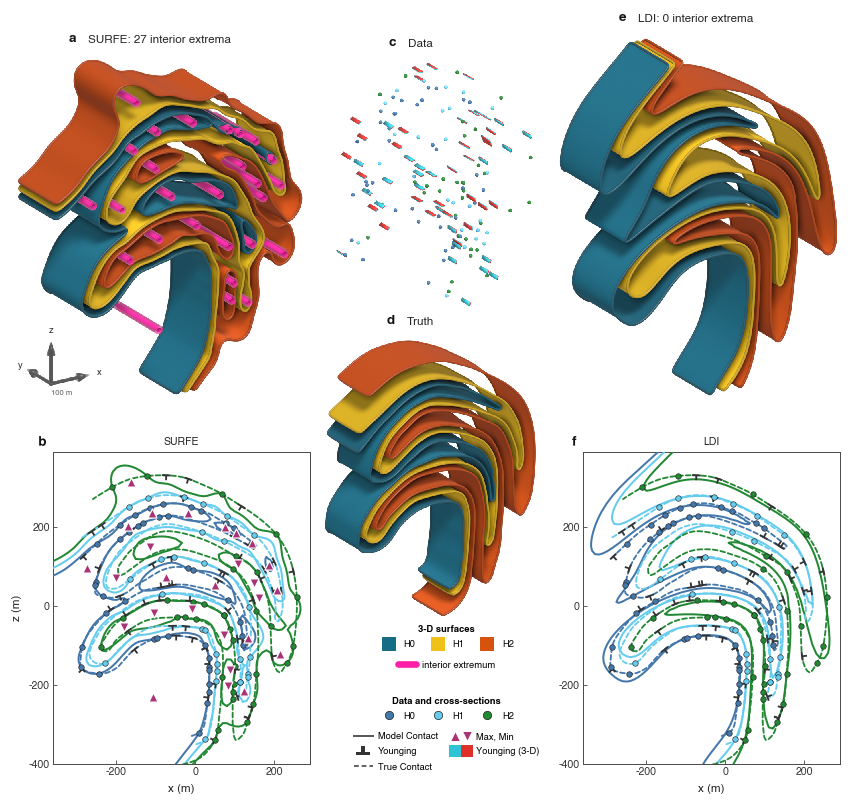

In [4]:
RENDER_W, TRUTH_W = 0.34, 0.28          # the data panel is the truth's size
TRUTH_UP = 0.7
DATA_TRUTH_GAP = -0.1     # in, from the data panel's bottom to the truth's top; negative pulls the truth up
                          # into the data panel's empty lower part (the panels are transparent)
SECTION_H, SECTION_GAP = 2.6, 0.45
YOUNG_SIZE = 26.0
KEY_GAP = 0.18             # in, between the two blocks of the key
TITLE_PAD = 10.0            # pt, between each render's title and the top of what it shows
DPI = 300

imgs = {k: np.asarray(Image.open(p).convert("RGBA")) for k, p in renders.items()}
alpha = np.maximum.reduce([im[..., 3] for im in imgs.values()])     # one crop for all, so all share a scale
rows, cols = np.flatnonzero(alpha.max(1) > 8), np.flatnonzero(alpha.max(0) > 8)
r0, r1 = max(rows[0] - 10, 0), min(rows[-1] + 11, alpha.shape[0])
c0, c1 = max(cols[0] - 10, 0), min(cols[-1] + 11, alpha.shape[1])
crop = {k: im[r0:r1, c0:c1] for k, im in imgs.items()}
aspect = (c1 - c0) / (r1 - r0)


def panel_pixels(arr, w_in, h_in):
    # Resample to the panel's size at DPI ourselves, on premultiplied alpha (no halo at the edges).
    size = (max(1, round(w_in * DPI)), max(1, round(h_in * DPI)))
    return np.asarray(Image.fromarray(arr).convert("RGBa").resize(size, Image.Resampling.LANCZOS).convert("RGBA"))


# Layout, measured down from the top of the page.
W = figstyle.PRINT_WIDTH
left, right, top, bottom = 0.16, 0.05, 0.30, 0.45
w3, wt = RENDER_W * W, TRUTH_W * W
h3, ht = w3 / aspect, wt / aspect
wd, hd = wt, ht                                                   # the data panel, as large as the truth
# the sections span the slab's x, within the x their fields cover
sec_lim = (max(slab[0, 0], *(v[0] for v in sec_x.values())), min(slab[1, 0], *(v[-1] for v in sec_x.values())))
w_sec = SECTION_H * (sec_lim[1] - sec_lim[0]) / np.ptp(z)
t_top = max(top + (1 - TRUTH_UP) * h3, top + hd + DATA_TRUTH_GAP)   # below the data panel and its title
s_top = top + h3 + SECTION_GAP                                   # both sections
H = s_top + SECTION_H + bottom
fig = figstyle.print_figure(height=H)
rect = lambda x0, t, w, h: (x0 / W, (H - t - h) / H, w / W, h / H)

panels = {"surfe": (left, top, w3, h3), "ldi": (W - right - w3, top, w3, h3),
          "data": (0.5 * (W - wd), top, wd, hd), "truth": (0.5 * (W - wt), t_top, wt, ht)}
n_ext = {k: len(extrema[k][0]) for k in fits}
titles = {"surfe": f"SURFE: {n_ext['surfe']} interior extrema", "ldi": f"LDI: {n_ext['ldi']} interior extrema",
          "data": "Data", "truth": "Truth"}
render_axes = []                         # (axes, letter): their letters go next to the titles at the end
LETTERS = {"surfe": "a", "surfe_section": "b", "data": "c", "truth": "d", "ldi": "e", "ldi_section": "f"}   # column by column
for zorder, key in enumerate(("surfe", "data", "ldi", "truth")):
    letter = LETTERS[key]
    x0, t, w, h = panels[key]
    ax = fig.add_axes(rect(x0, t, w, h), zorder=zorder)
    ax.imshow(panel_pixels(crop[key], w, h), interpolation="none")
    ax.set_axis_off()
    ax.patch.set_alpha(0.0)
    # the renders share one crop (one scale), so a render's own content can start well below the
    # top of its box: put the title just above the content, not above the box
    content = np.flatnonzero(crop[key][..., 3].max(1) > 8)
    y_title = 1.0 - (content[0] / crop[key].shape[0] if len(content) else 0.0)
    ax.set_title(titles[key], color="0.15", fontproperties=figstyle._fp(size=10), y=y_title, pad=TITLE_PAD)
    render_axes.append((ax, letter))

# the model axes, to the slabs' scale, at the bottom left of a
g = np.asarray(Image.open(gnomon_png).convert("RGBA"))
g_rows, g_cols = np.flatnonzero(g[..., 3].max(1) > 8), np.flatnonzero(g[..., 3].max(0) > 8)
gpad = 45
gr0, gr1, gc0, gc1 = g_rows[0] - gpad, g_rows[-1] + gpad + 1, g_cols[0] - gpad, g_cols[-1] + gpad + 1
px_per_in = (c1 - c0) / w3
gw, gh = (gc1 - gc0) / px_per_in, (gr1 - gr0) / px_per_in
gax = fig.add_axes(rect(left, top + h3 - gh, gw, gh), zorder=5)
gax.imshow(panel_pixels(g[gr0:gr1, gc0:gc1], gw, gh), interpolation="none", extent=(gc0, gc1, gr1, gr0))
pix = exploded3d.project(np.vstack([gnomon_origin, *gnomon_tips.values()]), cam, RESOLUTION)
for label, tip in zip("xyz", pix[1:]):
    at = tip + 0.25 * (tip - pix[0])
    gax.text(at[0], at[1], label, ha="center", va="center", fontproperties=figstyle._fp(size=8), color="0.2")
gax.text(pix[0][0], gr1 - 4, f"{GNOMON_LENGTH:.0f} m", ha="left", va="bottom", fontproperties=figstyle._fp(size=6.5),
         color="0.35")
gax.set_xlim(gc0, gc1); gax.set_ylim(gr1, gr0); gax.set_axis_off()

# the sections, under their renders
places = {"surfe": (left + 0.32, s_top), "ldi": (W - right - w_sec, s_top)}
for key in ("surfe", "ldi"):
    letter = LETTERS[f"{key}_section"]
    x0, t = places[key]
    ax = fig.add_axes(rect(x0, t, w_sec, SECTION_H), zorder=10)
    phi, iso = section[key], fits[key]["isovalues"]                 # isovalues in horizon order, youngest first
    for level, c in zip(iso, COLORS_2D):                             # each model contact in its horizon's colour
        for l in isocline_inputs.section_contours(sec_x[key], z, phi, level):
            ax.plot(*l.T, color=c, lw=1.2, zorder=3, solid_capstyle="round")
    for lines, c in zip(data["truth_lines"], COLORS_2D):
        for l in lines:
            ax.plot(*l.T, color=c, lw=1.1, ls=(0, (2.6, 1.6)), zorder=4, dash_capstyle="round")
    figstyle.draw_younging(ax, gp[:, [0, 2]], gv[:, [0, 2]], quiver_scale=1.0 / YOUNG_SIZE)
    for h, c in zip(horizons, COLORS_2D):
        ax.scatter(h[:, 0], h[:, 2], s=11, color=c, edgecolors="0.1", linewidths=0.35, zorder=6)
    p, kinds = extrema[key]
    for kind, marker in (("maximum", "^"), ("minimum", "v")):
        m = kinds == kind
        ax.scatter(p[m, 0], p[m, 1], marker=marker, s=30, c=EXT_2D, edgecolors="white", linewidths=0.7, zorder=7)
    ax.set_xlim(*sec_lim); ax.set_ylim(z[0], z[-1])
    figstyle.format_section_ax(ax, ylabel=True, title=f"{LABEL[key]}")
    ax.title.set_fontproperties(figstyle._fp(size=9))
    ax.set_xticks([-200, 0, 200]); ax.set_yticks([-400, -200, 0, 200])
    for side in ax.spines.values():
        side.set_linewidth(0.6); side.set_color("0.3")
    if key == "ldi":
        ax.set_ylabel("")

    figstyle.panel_label(ax, letter)

# The key, centred in the space between the sections: what the 3-D renders show under the truth,
# and what the sections show level with their bottom edge.
gap_l = places["surfe"][0] + w_sec                                # in, the free space between d and e
gap_r = places["ldi"][0]
x_key = 0.5 * (gap_l + gap_r) / W
common = dict(frameon=False, prop=figstyle._fp(size=8), title_fontproperties=figstyle._fp(bold=True, size=8),
              alignment="center", handletextpad=0.6, labelspacing=0.65, columnspacing=1.4, borderaxespad=0.0,
              handlelength=2.0, handler_map={tuple: HandlerTuple(ndivide=None, pad=0.5)})
level_labels = list(names)
x_t, t_t, w_t, h_t = panels["truth"]

# 3-D surfaces: the horizons in one row, then the extremum rods
squares = [(Line2D([], [], ls="", marker="s", ms=8, mfc=c, mec="none"), l) for c, l in zip(COLORS_3D, level_labels)]
leg_3d = fig.legend([h for h, _ in squares], [l for _, l in squares], title="3-D surfaces", ncol=len(squares),
                    loc="upper center", **common)
marks_3d = [(Line2D([], [], color=EXT_3D, lw=4.0, solid_capstyle="round"), "interior extremum")]
leg_rod = fig.legend([h for h, _ in marks_3d], [l for _, l in marks_3d], ncol=len(marks_3d),
                     loc="upper center", **common)

# cross-sections: the horizons in one row, then the marks two by two
dots = [(Line2D([], [], ls="", marker="o", ms=5, mfc=c, mec="0.1", mew=0.4), n) for c, n in zip(COLORS_2D, names)]
leg_2d = fig.legend([h for h, _ in dots], [l for _, l in dots], title="Data and cross-sections", ncol=len(dots),
                    loc="upper center", **common)
marks = [(Line2D([], [], color="0.35", lw=1.2), "Model Contact"),
         (Line2D([], [], ls="", marker=figstyle._younging_marker(), ms=8, mfc=figstyle.NORMAL_COLOR, mew=0), "Younging"),
         (Line2D([], [], color="0.35", lw=1.1, ls=(0, (2.6, 1.6))), "True Contact"),
         ((Line2D([], [], ls="", marker="^", ms=6, mfc=EXT_2D, mec="white", mew=0.6),
           Line2D([], [], ls="", marker="v", ms=6, mfc=EXT_2D, mec="white", mew=0.6)), "Max, Min"),
         ((Line2D([], [], ls="", marker="s", ms=7, mfc=BEDDING_COLORS[0], mec="none"),
           Line2D([], [], ls="", marker="s", ms=7, mfc=BEDDING_COLORS[1], mec="none")), "Younging (3-D)")]
leg_marks = fig.legend([h for h, _ in marks], [l for _, l in marks], ncol=2, loc="upper center", **common)

# stack the blocks (KEY_GAP between the 3-D and the section blocks, a line's gap inside each)
# and centre them between the truth and the sections' bottom
legs, gaps = (leg_3d, leg_rod, leg_2d, leg_marks), (0.05, KEY_GAP, 0.05)
fig.canvas.draw()
heights = [leg.get_window_extent().height / fig.dpi for leg in legs]                 # in
space_top, space_bottom = H - t_t - h_t - 0.10, bottom                               # in, from the bottom
y = space_top - 0.5 * ((space_top - space_bottom) - (sum(heights) + sum(gaps)))
for leg, h, g in zip(legs, heights, (*gaps, 0.0)):
    leg.set_bbox_to_anchor((x_key, y / H), transform=fig.transFigure)
    y -= h + g

# each render's letter just left of its title
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
for ax, letter in render_axes:
    bb = ax.title.get_window_extent(renderer).transformed(fig.transFigure.inverted())
    fig.text(bb.x0 - 0.10 / W, bb.y0, letter, ha="right", va="bottom", color="0.08",
             fontproperties=figstyle._fp(bold=True, size=8.0 / figstyle.TEXT_SCALE))

written = figstyle.save(fig, FIG_DIR / f"fig07_cylindrical_isocline{'' if SURFE_TAG == 'surfe' else '_' + SURFE_TAG}")
print("wrote", *written, sep="\n  ")
plt.show()